# ML Practical Session 4 – Overfitting, data leakage, generalization



In [8]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures, TargetEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split, TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

SEED = 42
rmse = lambda y, p: np.sqrt(mean_squared_error(y, p))
raw = pd.read_csv('student_performance.csv')

## Preparation (fixed mappings only – nothing is learned from the data here)

In [9]:
TARGET = 'final_score'
CGPA_MID = {'5.0 – 6.9': 5.95, '7.0 – 8.4': 7.7, '8.5 – 9.4': 8.95, '9.5 – 10.0': 9.75}


ORDER = {
    'study_hours_daily': ['Less than 1 hour', '1–2 hours', 'More than 2 hours'],
    'sleep_hours': ['4–5 hours', '6–7 hours', 'More than 8 hours'],
    'attendance_percentage': ['Less than 50%', '50% – 65%', '66% – 75%', '76% – 85%', 'Above 85%'],
    'revision_frequency': ['Never', 'Rarely', 'Few times a week', 'Daily'],
    'focus_duration': ['30–60 minutes', '1–2 hours', 'More than 2 hours'],
    'screen_time_non_study': ['2–4 hours', '4–6 hours', 'More than 6 hours'],
    'study_consistency': ['Rarely', 'Sometimes', 'Mostly consistent'],
    'tasks_on_time': ['Rarely', 'Sometimes', 'Often', 'Always'],
    'assignments_on_time': ['Rarely', 'Sometimes', 'Often', 'Always'],
    'sleepy_during_study': ['Never', 'Sometimes', 'Often', 'Always'],
    'academic_satisfaction': ['Very unsatisfied', 'Unsatisfied', 'Neutral', 'Satisfied', 'Very satisfied'],
    'career_goal_clarity': ['Not clear', 'Somewhat clear', 'Very clear'],
    'external_resources': ['Never (Unaware or Not interested)', 'Rarely (Passive)', 'Occasionally (When needed)'],
    'external_pressure': ['No Impact (Fully supportive environment)', 'Low Impact (Rarely affects study)',
                          'Moderate Impact (Occasional disruption)', 'High Impact (Frequent disruption)'],
}
NOM = ['gender', 'year_class', 'main_distractor', 'preparation_status', 'skills_developing', 'career_interest',
       'online_courses', 'projects_internships', 'programming_foundation', 'events_participation',
       'strongest_asset', 'internal_barrier']
HC = 'program_stream'      
MIN_COUNT = 100           

df = raw.copy()
df['timestamp'] = pd.to_datetime(df['timestamp'], format='%m/%d/%Y %H:%M:%S')
df[TARGET] = df['cgpa_category'].map(CGPA_MID)
for c, order in ORDER.items():
    df[c + '_n'] = df[c].map({v: i for i, v in enumerate(order)})
df['days'] = (df['timestamp'] - pd.Timestamp('1970-01-01')).dt.total_seconds() / 86400

items = {'study_hours_daily_n': 2, 'study_consistency_n': 2, 'revision_frequency_n': 3, 'focus_duration_n': 2}
df['study_effort'] = pd.concat([df[c] / m for c, m in items.items()], axis=1).mean(axis=1)
df[NOM + [HC]] = df[NOM + [HC]].astype(object)

NUM = ['age', 'daily_productivity', 'energy_level', 'stress_level', 'routine_rating', 'days', 'study_effort'] + [c + '_n' for c in ORDER]
COLS = NUM + NOM + [HC]       

df = df.sort_values('timestamp', kind='stable').reset_index(drop=True)      
print(len(COLS), 'features | target =', TARGET)

34 features | target = final_score


# Part A – Data inspection

(1200, 36)
str        31
float64     4
int64       1
Name: count, dtype: int64


,age,daily_productivity,energy_level,stress_level,routine_rating
count,1200.000000,1166.000000,1172.000000,1165.000000,1159.000000
mean,20.807500,2.686964,3.227816,3.151931,2.105263
std,2.186953,1.178761,1.145359,1.189194,0.788057
min,17.000000,1.000000,1.000000,1.000000,1.000000
25%,19.000000,2.000000,2.000000,2.000000,1.000000
50%,21.000000,3.000000,3.000000,3.000000,2.000000
75%,22.000000,3.000000,4.000000,4.000000,3.000000
max,26.000000,5.000000,5.000000,5.000000,3.000000



Missing values:
 daily_productivity        34
revision_frequency        34
focus_duration            43
screen_time_non_study     32
energy_level              28
stress_level              35
routine_rating            41
sleep_hours               55
online_courses            36
programming_foundation    41
events_participation      58
external_resources        45
external_pressure         29
dtype: int64

Duplicates (with id): 0 | without id and timestamp: 0


,corr with target
age,-0.024
external_resources_n,-0.013
sleep_hours_n,-0.010
energy_level,-0.005
sleepy_during_study_n,-0.004
stress_level,0.019
days,0.020
screen_time_non_study_n,0.033
external_pressure_n,0.038
focus_duration_n,0.048


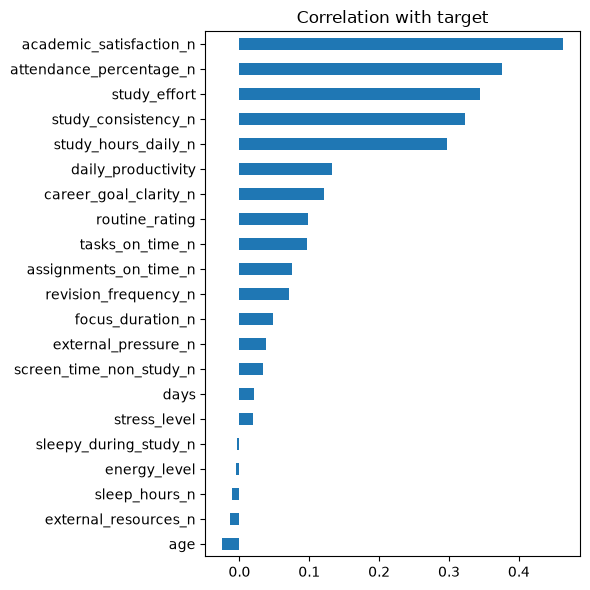


CGPA vs performance_risk_level:


performance_risk_level,High Risk,Low Risk,Moderate Risk
cgpa_category,,,
5.0 – 6.9,188,0,48
7.0 – 8.4,221,4,195
8.5 – 9.4,39,89,234
9.5 – 10.0,4,83,95


program_stream
BCA                     696
BSc Computer Science    129
BSc IT                   98
BCom                     87
BBA                      69
BSc Cyber Security       68
BA                       53
Name: count, dtype: int64
Categories with < 10 students: 0 | with < 100 : 5


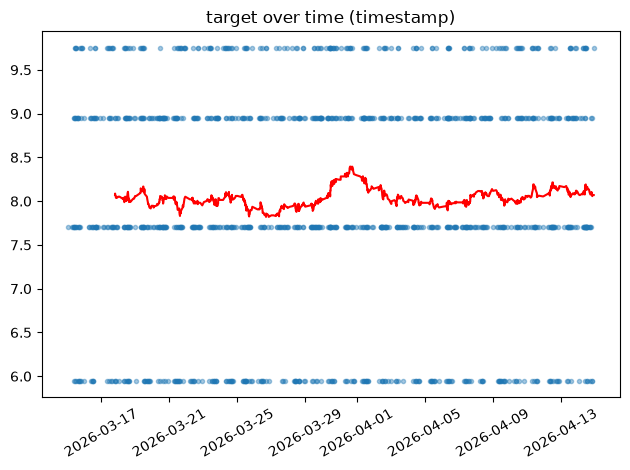

Timestamps already sorted in the file? False | corr(target, days) = 0.02


In [10]:
print(raw.shape); print(raw.dtypes.value_counts()); display(raw.describe())
miss = raw.isna().sum(); print('\nMissing values:\n', miss[miss > 0])

print('\nDuplicates (with id):', raw.duplicated().sum(),
      '| without id and timestamp:', raw.drop(columns=['student_id', 'timestamp']).duplicated().sum())

corr = df[NUM + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
display(corr.round(3).to_frame('corr with target'))
corr.plot.barh(figsize=(6, 6), title='Correlation with target'); plt.tight_layout(); plt.show()

print('\nCGPA vs performance_risk_level:'); display(pd.crosstab(raw['cgpa_category'], raw['performance_risk_level']))

counts = df[HC].value_counts(); print(counts)
print('Categories with < 10 students:', (counts < 10).sum(), '| with <', MIN_COUNT, ':', (counts < MIN_COUNT).sum())

plt.plot(df['timestamp'], df[TARGET], '.', alpha=.4); plt.plot(df['timestamp'], df[TARGET].rolling(100).mean(), 'r')
plt.title('target over time (timestamp)'); plt.xticks(rotation=30); plt.tight_layout(); plt.show()
print('Timestamps already sorted in the file?', raw['timestamp'].pipe(pd.to_datetime, format='%m/%d/%Y %H:%M:%S').is_monotonic_increasing,
      '| corr(target, days) =', round(df[[TARGET, 'days']].corr().iloc[0, 1], 3))

**Risks found**
- `performance_risk_level` is computed from CGPA (see the crosstab) → using it as a feature = **target leakage**, so it is excluded.
- No exact duplicates in the file, but any duplicated survey row would leak between train and test (shown in B.2 with injected copies).
- Missing answers in ~15 columns → imputation statistics must be learned on training data only (inside the Pipeline).
- `program_stream` has small categories (e.g. BA, BSc Cyber Security) → one-hot columns for them can be memorised (overfitting).
- Timestamps cover ~1 month and are not sorted in the file; no visible drift, but a random split would still mix "past" and "future".
- The target has only 4 distinct values, so RMSE cannot go below the spread inside each CGPA band.

# Part B – Data leakage

In [11]:
def make_pipe(model, hc='onehot', scale=False):
    num = Pipeline([('imp', SimpleImputer(strategy='median'))] + ([('sc', StandardScaler())] if scale else []))
    nom = Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    parts = [('num', num, NUM), ('nom', nom, NOM)]
    if hc == 'onehot':
        parts.append(('hc', OneHotEncoder(handle_unknown='ignore', sparse_output=False), [HC]))
    elif hc == 'group':    # categories with < MIN_COUNT training rows are merged into one "infrequent" column
        parts.append(('hc', OneHotEncoder(min_frequency=MIN_COUNT, handle_unknown='infrequent_if_exist', sparse_output=False), [HC]))
    elif hc == 'target':   # out-of-fold target encoding (done inside fit)
        parts.append(('hc', TargetEncoder(cv=5, shuffle=False, target_type='continuous'), [HC]))
    return Pipeline([('prep', ColumnTransformer(parts)), ('model', model)])

def run(pipe, tr, te):
    pipe.fit(tr[COLS], tr[TARGET])
    p_tr, p_te = pipe.predict(tr[COLS]), pipe.predict(te[COLS])
    return rmse(tr[TARGET], p_tr), rmse(te[TARGET], p_te), r2_score(te[TARGET], p_te)

def chrono(d):
    n = int(len(d) * 0.8)
    return d.iloc[:n], d.iloc[n:]

def rand(d):
    return train_test_split(d, test_size=0.2, random_state=SEED)

summary = []
tree = lambda: make_pipe(DecisionTreeRegressor(random_state=SEED))


for name, split in [('Random split', rand), ('Chronological split', chrono)]:
    tr, te = split(df); a, b, _ = run(tree(), tr, te); summary.append((f'B.1 {name}', a, b))


df_clean = df.drop_duplicates(subset=COLS + [TARGET]).reset_index(drop=True)
df_dup = pd.concat([df_clean, df_clean.sample(120, random_state=SEED)]).sort_values('timestamp', kind='stable').reset_index(drop=True)
print('Real duplicates removed:', len(df) - len(df_clean), '| injected copies:', len(df_dup) - len(df_clean))
for sname, split in [('random', rand), ('chrono', chrono)]:
    for name, d in [('split before removing duplicates', df_dup), ('remove duplicates before split', df_clean)]:
        tr, te = split(d); a, b, _ = run(tree(), tr, te); summary.append((f'B.2 {sname}: {name}', a, b))


n = int(len(df_clean) * 0.8)
X = df_clean[NUM]; X = X.fillna(X.median()); y = df_clean[TARGET]
Xs = StandardScaler().fit_transform(X)                                  
m = KNeighborsRegressor(5).fit(Xs[:n], y[:n])
summary.append(('B.3 scaler fit on ALL data (leaky)', rmse(y[:n], m.predict(Xs[:n])), rmse(y[n:], m.predict(Xs[n:]))))
tr, te = chrono(df_clean)                                              
pipe = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('m', KNeighborsRegressor(5))])
pipe.fit(tr[NUM], tr[TARGET])
summary.append(('B.3 scaler fit on TRAIN only (Pipeline)', rmse(tr[TARGET], pipe.predict(tr[NUM])), rmse(te[TARGET], pipe.predict(te[NUM]))))

display(pd.DataFrame(summary, columns=['strategy', 'training RMSE', 'testing RMSE']).round(3))

Real duplicates removed: 0 | injected copies: 120


,strategy,training RMSE,testing RMSE
0,B.1 Random split,0.000,1.549
1,B.1 Chronological split,0.000,1.449
2,B.2 random: split before removing duplicates,0.000,1.324
3,B.2 random: remove duplicates before split,0.000,1.549
4,B.2 chrono: split before removing duplicates,0.000,1.469
5,B.2 chrono: remove duplicates before split,0.000,1.449
6,B.3 scaler fit on ALL data (leaky),0.946,1.104
7,B.3 scaler fit on TRAIN only (Pipeline),0.946,1.107


**B.1** A random split puts students from the same period in both sets, so a fully grown tree looks better than it is. The chronological split tests on later students and gives the honest estimate.

**B.2** A duplicated row can be split so that one copy is in train and the other in test (about 32 % of pairs with an 80/20 split). The model has already seen the answer, so the test score is too good. Remove duplicates before splitting.

**B.3** Mean and standard deviation computed on all data contain information about the test rows. Learn them from training data only (Pipeline). Trees ignore scaling, so KNN is used to show the effect.

# Part C – Overfitting

Train: 960 | Test: 240


,max_depth,train RMSE,test RMSE,gap
0,1,1.169,1.122,-0.046
1,2,1.083,1.079,-0.005
2,3,1.035,1.070,0.036
3,5,0.936,1.172,0.236
4,10,0.421,1.400,0.979
5,20,0.000,1.449,1.449
6,None,0.000,1.449,1.449


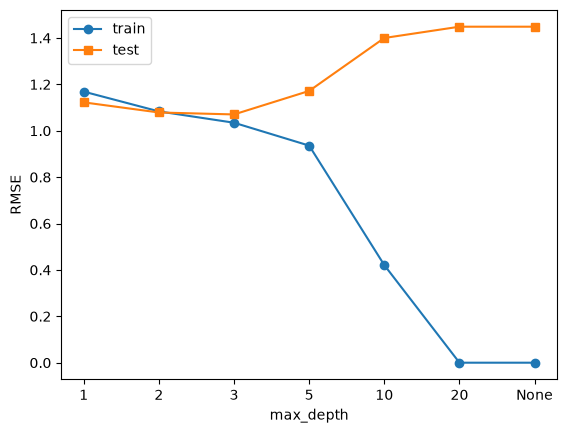

Lowest test RMSE at max_depth = 3 - deeper trees overfit (train falls, test rises, gap grows).


,degree,CV RMSE
0,1,1.196
1,2,1.199
2,3,1.200
3,5,1.202
4,9,1.202
5,15,1.208


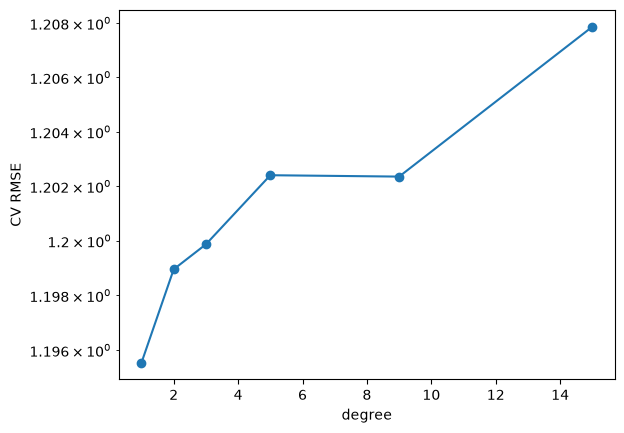

Best degree by CV: 1


In [12]:
train, test = chrono(df_clean)     
print('Train:', len(train), '| Test:', len(test))


rows = []
for d in [1, 2, 3, 5, 10, 20, None]:
    a, b, _ = run(make_pipe(DecisionTreeRegressor(max_depth=d, random_state=SEED)), train, test)
    rows.append({'max_depth': str(d), 'train RMSE': a, 'test RMSE': b, 'gap': b - a})
c1 = pd.DataFrame(rows); display(c1.round(3))
plt.plot(c1['max_depth'], c1['train RMSE'], 'o-', label='train'); plt.plot(c1['max_depth'], c1['test RMSE'], 's-', label='test')
plt.xlabel('max_depth'); plt.ylabel('RMSE'); plt.legend(); plt.show()
best = c1['test RMSE'].idxmin()
print('Lowest test RMSE at max_depth =', c1['max_depth'][best], '- deeper trees overfit (train falls, test rises, gap grows).')


tscv = TimeSeriesSplit(n_splits=5)
rows = []
for deg in [1, 2, 3, 5, 9, 15]:
    p = Pipeline([('imp', SimpleImputer(strategy='median')), ('poly', PolynomialFeatures(deg, include_bias=False)),
                  ('sc', StandardScaler()), ('lr', LinearRegression())])
    s = -cross_val_score(p, train[['study_effort']], train[TARGET], cv=tscv, scoring='neg_root_mean_squared_error')
    rows.append({'degree': deg, 'CV RMSE': s.mean()})
c2 = pd.DataFrame(rows); display(c2.round(3))
plt.plot(c2['degree'], c2['CV RMSE'], 'o-'); plt.xlabel('degree'); plt.ylabel('CV RMSE'); plt.yscale('log'); plt.show()
print('Best degree by CV:', c2['degree'][c2['CV RMSE'].idxmin()])

**C.1** Shallow trees underfit. As depth grows, training error goes to ~0 while test error stops improving and then rises: the growing gap shows overfitting.

**C.2** Low degrees underfit, a moderate degree fits well, and very high degrees fit noise, so the CV error grows.

# Part D – Improving generalization

In [13]:

res = {}
for name, mode in [('Rare-category grouping', 'group'), ('Target encoding (out-of-fold)', 'target'), ('Feature removal', 'drop')]:
    if mode == 'drop':                       
        keep = [c for c in COLS if c != HC]
        pipe = Pipeline([('prep', ColumnTransformer([
            ('num', Pipeline([('imp', SimpleImputer(strategy='median'))]), NUM),
            ('nom', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                              ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), NOM)])),
            ('model', DecisionTreeRegressor(max_depth=5, random_state=SEED))]).fit(train[keep], train[TARGET])
        res[name] = rmse(test[TARGET], pipe.predict(test[keep]))
    else:
        res[name] = run(make_pipe(DecisionTreeRegressor(max_depth=5, random_state=SEED), hc=mode), train, test)[1]
display(pd.Series(res, name='test RMSE').round(3))
best_mode = {'Rare-category grouping': 'group', 'Target encoding (out-of-fold)': 'target'}.get(min(res, key=res.get), 'onehot')
print('Best treatment:', min(res, key=res.get), '(used below; feature removal falls back to plain one-hot for simplicity)')


P = ['study_effort', 'attendance_percentage_n', 'academic_satisfaction_n', 'daily_productivity']
def poly_pipe(model):
    return Pipeline([('imp', SimpleImputer(strategy='median')), ('sc0', StandardScaler()),
                     ('poly', PolynomialFeatures(5, include_bias=False)), ('sc', StandardScaler()), ('model', model)])
alphas = {'model__alpha': [0.001, 0.01, 0.1, 1, 10, 100]}
ridge = GridSearchCV(poly_pipe(Ridge()), alphas, cv=tscv, scoring='neg_root_mean_squared_error').fit(train[P], train[TARGET])
lasso = GridSearchCV(poly_pipe(Lasso(max_iter=20000)), alphas, cv=tscv, scoring='neg_root_mean_squared_error').fit(train[P], train[TARGET])
lin = poly_pipe(LinearRegression()).fit(train[P], train[TARGET])
print('Best Ridge alpha:', ridge.best_params_, '| CV RMSE', round(-ridge.best_score_, 3))
print('Best Lasso alpha:', lasso.best_params_, '| CV RMSE', round(-lasso.best_score_, 3))
for name, m in [('Linear', lin), ('Ridge', ridge.best_estimator_), ('Lasso', lasso.best_estimator_)]:
    w = m.named_steps['model'].coef_
    print(f'{name:7s} max|coef| = {np.abs(w).max():10.3f} | zero coefs = {(np.abs(w) < 1e-10).sum()} of {len(w)}')

Rare-category grouping           1.172
Target encoding (out-of-fold)    1.169
Feature removal                  1.169
Name: test RMSE, dtype: float64

Best treatment: Target encoding (out-of-fold) (used below; feature removal falls back to plain one-hot for simplicity)
Best Ridge alpha: {'model__alpha': 100} | CV RMSE 1.109
Best Lasso alpha: {'model__alpha': 0.1} | CV RMSE 1.04
Linear  max|coef| =      0.954 | zero coefs = 0 of 125
Ridge   max|coef| =      0.275 | zero coefs = 0 of 125
Lasso   max|coef| =      0.397 | zero coefs = 122 of 125


Ridge shrinks all coefficients towards zero; Lasso shrinks them and sets many exactly to zero (feature selection). Both are smaller and more stable than plain Linear Regression.

In [14]:

reg = ridge if ridge.best_score_ >= lasso.best_score_ else lasso
reg_name = 'Ridge' if reg is ridge else 'Lasso'
tree_gs = GridSearchCV(make_pipe(DecisionTreeRegressor(random_state=SEED), hc=best_mode),
                       {'model__max_depth': [2, 3, 5, 7, 10], 'model__min_samples_leaf': [1, 5, 10, 20]},
                       cv=tscv, scoring='neg_root_mean_squared_error').fit(train[COLS], train[TARGET])
gb = make_pipe(GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, n_iter_no_change=10,
                                         validation_fraction=0.15, random_state=SEED), hc=best_mode)

rows = {}
for name, m, cols in [('Linear Regression', lin, P), (f'{reg_name} (tuned alpha)', reg.best_estimator_, P),
                      ('Decision Tree (tuned)', tree_gs.best_estimator_, COLS),
                      ('Gradient Boosting (early stopping)', gb, COLS)]:
    m.fit(train[cols], train[TARGET])                       
    a, b = rmse(train[TARGET], m.predict(train[cols])), rmse(test[TARGET], m.predict(test[cols]))
    rows[name] = {'Training RMSE': a, 'Testing RMSE': b, 'Testing R²': r2_score(test[TARGET], m.predict(test[cols])), 'Gap': b - a}
final = pd.DataFrame(rows).T; display(final.round(3))
print('Best generalization :', final['Testing RMSE'].idxmin())
print('Largest gap         :', final['Gap'].idxmax())

,Training RMSE,Testing RMSE,Testing R²,Gap
Linear Regression,0.948,1.069,0.250,0.121
Lasso (tuned alpha),1.034,1.002,0.340,-0.031
Decision Tree (tuned),1.083,1.079,0.236,-0.005
Gradient Boosting (early stopping),0.905,0.985,0.363,0.080


Best generalization : Gradient Boosting (early stopping)
Largest gap         : Linear Regression


# Final discussion
1. **Best generalization:** the model with the lowest testing RMSE in the table above (printed as "Best generalization").
2. **Largest gap:** the model printed as "Largest gap" – its training error is much lower than its testing error.
3. **Most effective techniques:** limiting tree depth, regularization (Ridge/Lasso) instead of plain high-degree polynomials, a moderate polynomial degree, grouping/encoding rare categories, early stopping for boosting, and removing the leaking `performance_risk_level`.
4. **Validation, not training:** training error rewards memorising (a full tree has ~0 training error). Validation error estimates performance on unseen data, so it is the fair way to pick a model.
5. **Untouched test set:** if we choose models using the test set, it becomes part of training and the final score is too optimistic. Here, hyper-parameters were chosen with TimeSeriesSplit on training data only.